# Второй курс, первый семестр
## Рабочая тетрадь №1

# **Подготовка данных**

## Фильтрация

Обучающая выборка может содержать как типичные, так и нетипичные объекты, называемые **выбросами** (outliers) и **аномалиями** (anomaly). Чтобы настроить модель устойчивее обрабатывать именно типичные случаи, необходимо провести предварительную **фильтрацию выбросов**. Существуют отдельный класс методов, позволяющий идентифицировать объекты-выбросы сразу по всему вектору признаков, однако для первичной обработки может использоваться и простой анализ распределений каждого признака в отдельности.

Если вывести по убыванию популярности ИИ-инструменты датасета `Students.csv` без предобработки, полученные данные будут искажены:

In [2]:
tool_counts = df['AI_Tools_Used'].value_counts()
print(tool_counts)

ChatGPT                     626
Gemini                      612
Copilot                     585
ChatGPT, Copilot            505
ChatGPT, Gemini, Copilot    426
Gemini, Midjourney          371
Claude                      171
Other                       167
Bard                        151
Name: AI_Tools_Used, dtype: int64


## Заполнение пропусков в данных

При измерении признаков объектов, некоторые из них могут отсутствовать. В этом случае вектор признаков будет содержать **пропуски** (missing values). При этом большинство моделей машинного обучения требуют для обработки полный вектор признаков без пропусков.

Простейшим выходом при работе с пропусками могло бы быть исключение всех объектов, у которых хотя бы один из признаков не указан. Этот приём подходит, если число объектов с пропущенными значениями невелико относительно общего объема выборки. Если же таких объектов много, то нужно выработать **метод заполнения пропущенных значений** (missing data imputation)

### Пропуски в категориальных и бинарных признаках

Для категориальных признаков, принмающих одно из *n* дискретных значений, пропуски можно заполнить:

- максимально частой категорией (в статистике это называется **модой распределения** - mode imputation).
- новой категорией **[пропуск]**.

Второй способ подходит больше в случаях, когда число категорий велико, и нет оснований во всех неопределённых случаях предпочитать самую частую категорию.

Более продвинутая техника заключается в предсказании пропущенной категории отдельным классификатором, обученным предсказывать значение признака с пропусками по оставшимся известным признакам, что позволяет заполнять значения не константой, а переменной величиной в зависимости от других характеристик объекта.

### Пропуски в вещественных признаках

Для вещественных признаков пропуски можно заполнять

- выборочным средним:
$$
mean(x) = \frac{1}{n} \sum_{i=1}^{n} x_{i}.
$$
- выборочной медианой:
$$
\left\{ 
\begin{array}{ll}
median(x) = \frac{x_{n/2} + x_{n/2 + 1}}{2}  \text{ - для четного n;} \\
median(x) = x_{(n+1)/2} \text{ - для нечетного n.}
\end{array} 
\right.
$$

Выборочные статистики считаются по присутствующим значениям признака в других объектах. Медиана более предпочтительна, поскольку является мерой оценки центра распределения, устойчивой к наличию выбросов (robust to outliers), в отличие от среднего.

## Обработка категориальных признаков

**Категориальные признаки** (categorical features) - это признаки, принимающие одно из $n$ дискретных значений. Такие признаки часто встречаются на практике. Частным случаем категориальных признаков являются бинарные признаки (binary features), принимающие всего два значения.

Модель машинного обучения ожидает на входе вектор, состоящий только из вещественных признаков. Бинарный признак представим в вещественном виде, закодировав категории цифрами $0$ и $1$, однако, в случае признака, описывающего несколько категорий, возможны различные варианты кодировок.

### Порядковое кодирование

В порядковом кодировании (ordinal encoding) категория заменяется её номером $\text{(0, 1, 2, 3, и т.д.)}$.

Этот вариант может негативно повлиять на работу метода машинного обучения, который впоследствии будет считать, что движение в направлении $\text{0, 1, 2, 3, ...}$ будет соответствовать возрастанию какой-то реально существующей характеристики, которой в действительности нет, поскольку нумерация была произвольной. Также метод на основе близости численных значений будет считать может неправильно формировать близость объектов.

### Кодирование частотами

При **частотном кодировании** (frequency encoding) значение каждой категории заменяется на частоту встречаемости этой категории $\text{(1/10, 2/11, 3/13, и т.д.)}$. Полезность кодировки определяется тем, насколько частота встречаемости категорий связана с целевой переменной.

### One-hot кодирование

При **one-hot кодировании** (one-hot encoding, dummy encoding) все категории нумеруются произвольным образом. Каждый категориальный признак, принимающий значение i-й категории среди n возможных, кодируется n-мерным вектором из нулей, где на одной только i-й позиции стоит единица.

Метод однозначно кодирует категорию и, в отличие от предыдущих методов, производит сопоставление одному категориальному признаку сразу набор бинарных признаков (по числу категорий). Все категории, независимо от порядка кодирования, получаются равнозначными: попарное расстояние между кодировками любой пары категорий получается одним и тем же.

One-hot кодирование - самый популярный способ представления категориальных признаков, однако у него есть недостаток, что при слишком большом числе категорий он приводит к сильному разрастанию числа признаков. Одним из способов борьбы с этим является объединение различных родственных категорий в одну.

### Кодирование средним

Кодирование средним (mean encoding, target encoding) - компактный и максимально информативный способ кодирования категориального признака путём замены каждой категории на среднее прогнозируемого отклика при условии этой категории.

Для регрессии и бинарной классификации один столбец исходного признака заменяется на один столбец условных средних. В случае многоклассовой классификации каждая категория будет заменяться на вектор условных частот каждого из классов при условии категории.

Данный способ кодирования максимально информативен для решения итоговой задачи предсказания отклика по кодировке, поскольку кодировка в явном виде агрегирует информацию об отклике.

### Кодирование циклических переменных

Моделировать такие виды близости можно с помощью циклического кодирования, при котором признак $ u∈[0, \max{u}) $ кодируется парой вещественных значений:
$$
u \to \left[sin\left(\frac{2\pi*u}{\max{u}}\right); cos\left(\frac{2\pi*u}{\max{u}}\right)\right]
$$
Поскольку $sin()$ и $cos()$ - непрерывные функции, то такое представление для близких значений  будет выдавать близкие кодировки. Эффект достигается за счёт свойств периодичности синуса и косинуса.

# Нормализация признаков

Для большинства методов машинного обучения масштаб признаков оказывают влияние на прогноз. Для таких моделей чем выше разброс значений признака, тем сильнее он будет влиять на прогноз, перекрывая влияние признаков меньшего масштаба.

Чем выше разброс вдоль определённого признака, тем сильнее он влияет на прогноз, поэтому, чтобы влияние всех признаков было одинаковым, их необходимо нормализовать, то есть привести к одному масштабу. Наиболее популярным методом нормализации признака является **стандартизация** признака (standardization, standard scaler).

Вторым по популярности является **диапазонное шкалирование** (min-max scaler) - значения признака из отрезка $ [min, max] $ переводятся в отрезок $ [0, 1] $, причём если минимальное значение признака - нулевое, то оно не меняется, что полезно для разреженных данных (sparse data), в которых большинство значений - нули. Такие данные часто возникают на практике и эффективно кодируются разреженными матрицами, которые экономично их хранят и производят операции над ними, оперируя только ненулевыми элементами. Диапазонное шкалирование позволяет сохранить свойство разреженности.

- Стандартизация:
$$
\frac{x_i - \mu}{\sigma}.
$$
- Диапазонное шкалирование:
$$
\frac{x_i - \min{x}}{\max{x}-\min{x}}.
$$
- Нормализация средним:
$$
\frac{x_i - \mu}{\max{x}-\min{x}},
$$
где $ \mu = \frac{\sum_{i = 1}^n x_i}{n} $ - среднее значение набора данных; a $ \sigma = \sqrt{\frac{\sum_{i = 1}^n (x_i - \mu)^2}{n}} $.

Каждый вид шкалирования применяется к каждому признаку независимо.

### Влияние выбросов

Наличие выбросов (аномально больших или малых значений) искажает результат нормализации, так наличие даже одного выброса может существенно сместить среднее, дисперсию, минимум или максимум. Поэтому важно предварительно отфильтровать выбросы из выборки. Альтернативно можно заменить неустойчивые к выбросам статистики на устойчивые:

- Центр распределения: $ \frac{\sum_{i = 1}^n x_i}{n} \rightarrow median(x) $.
- Разброс распределения: $ \sqrt{\frac{\sum_{i = 1}^n x_i^2}{n}} \rightarrow median(|x - median(x)|)$.
- Минимум: $ \min{x} \rightarrow 1\%\space перцентиль $.
- Максимум: $ \max{x} \rightarrow 99\%\space перцентиль $.

### Медиана

**Медиана** (median) - величина, альтернативная выборочному среднему (mean) для оценки центра распределения. Для выборки значений признака медиана - это такое значение, что половина наблюдений оказываются меньше, а другая половина - больше этого значения. Для вероятностного распределения медиана - это такое значение, что половина вероятностной массы лежит слева, а другая половина - справа от значения медианы.

### p-процентная перцентиль

p-процентная перцентиль (percentile) - это такое значение, что:

- Для выборки наблюдений $ p $ процентов наблюдений лежит слева, а $ 100 − p $ процентов - справа от значения;
- для вероятностного распределения признак с вероятностью $ p/100 $ принимает значение меньше, а с вероятностью $ \frac{100 − p}{100} $ - больше значения перцентили.

Медиана = 5.29
1-й перцентиль = 0.33
99-й перцентиль = 9.82


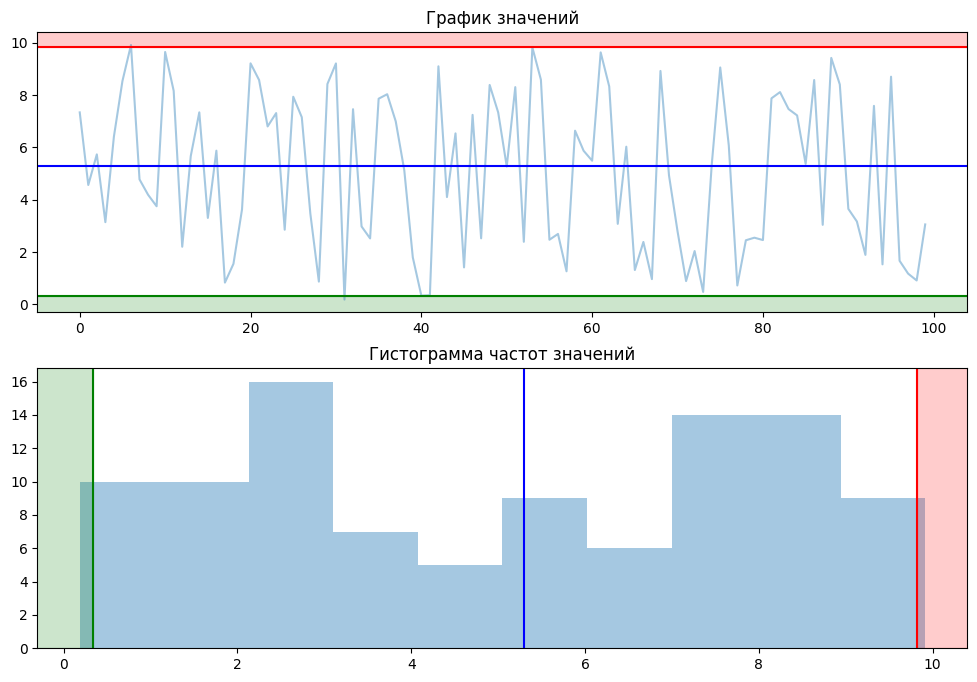

In [3]:
import matplotlib.pyplot as plt
import numpy as np

data = np.random.uniform(0, 10, 100)
median = np.median(data)
p01= np.percentile(data, 1)  # 1-й перцентиль
p99 = np.percentile(data, 99)  # 99-й перцентиль
print(f'Медиана = {median:.2f}\n1-й перцентиль = {p01:.2f}\n99-й перцентиль = {p99:.2f}')

plt.figure(figsize=(12, 8))
plt.subplot(2, 1, 1)
plt.plot(data, alpha = 0.4)
plt.axhline(median, color='b')
plt.axhline(p01, color='g')
plt.axhline(p99, color='r')

plt.title('График значений')
plt.gca().add_patch(plt.Rectangle((-20, -20), 140, p01 + 20, color='g', alpha=0.2))
plt.gca().add_patch(plt.Rectangle((-20, p99), 140, p99, color='r', alpha=0.2))

plt.subplot(2, 1, 2)
plt.hist(data, bins = 10, alpha = 0.4)
plt.axvline(median, color='b')
plt.axvline(p01, color='g')
plt.axvline(p99, color='r')

plt.title('Гистограмма частот значений')
plt.gca().add_patch(plt.Rectangle((-2, 0), 2 + p01, 25, color='g', alpha=0.2))
plt.gca().add_patch(plt.Rectangle((p99, 0), 4, 25, color='r', alpha=0.2))

plt.show()

# Генерация признаков

Исходных признаков может оказаться недостаточно для построения точной модели. Например, линейные методы моделируют только линейные зависимости отклика от признаков, а реальная зависимость может быть нелинейной, поэтому модель будет работать неточно. Для повышения точности моделей генерируют **новые признаки** из существующих (feature engineering). Признаки необходимо генерироватьс наибольшим их соответстветствием фрагментам реальной зависимости в данных, из которых модель уже соберёт итоговое решение.

### Подходы для генерации новых признаков

Можно генерировать признаки, соответствующие интерпретируемым характеристикам, влияющим на отклик. Такие алгоритмы, как решающие деревья, способны самостоятельно извлекать подобные признаки, но им сложно аппроксимировать линейные комбинации над признаками, поэтому им на вход можно подавать эти комбинации в явном виде как разности и суммы исходных признаков. Метрические алгоритмы предсказывают отклик только на основе попарных расстояний между объектами. Поэтому им рекомендуется расширение числа признаков как их разумной дискретизацией, так и линейными комбинациями над признаками. Линейным моделям и решающим деревьям можно дополнительно подавать на вход расстояния от каждого объекта до некоторого набора характерных объектов выборки (эталонов).

В качестве признаков модели могут выступать прогнозы других моделей, тогда итоговая модель будет учиться агрегировать прогнозы этих моделей наилучшим образом и будет называться **ансамблем** или **композицией** моделей (model ensemble). Чтобы избежать переобучения за счёт повторного переиспользования информации об откликах, базовые и агрегирующая разных модель должны обучаться на разных выборках, что реализуется в блендинге и стэкинге.

Увеличение числа признаков повышает вероятность настроиться на ложную зависимость (false dependency) между одним из признаков и откликом, которая будет соответствовать не реальной зависимости, а случайному совпадению в данных.

# Сокращение числа признаков

Исходных признаков может быть слишком много в силу избыточного сбора даже слабоинформативных данных. Либо могло появиться много новых признаков после их генерации из существующих.

Если число входных признаков велико, то их количество сокращается:

- методами **отбора признаков** (feature selection);
- методами **снижения размерности** (dimensionality reduction).

При отборе признаков используется **подмножество из исходных признаков**, а остальные просто отбрасываются. При снижении размерности каждый **выходной признак получается некоторым преобразованием** над всеми исходными признаками.



Существует много методов отбора признаков:

### 1. Удаление признаков с низкой дисперсией:

Алгоритм используется для отбора **признаков** (фичей) в данных на основе их дисперсии. Он удаляет признаки, дисперсия которых не превышает заданный порог, что применяется для исключения малополезных признаков.

В матрице признаков:
$$
X \in \mathbb{R}^{n \times m},
$$
где: $ n $ — количество объектов (строк); $ m $ — количество признаков (столбцов).

Для каждого признака $ j $ вычисляется его **дисперсия**:
$$
\sigma_j^2 = \frac{1}{n} \sum_{i=1}^n (x_{ij} - \mu_j)^2,
$$
где: $ x_{ij} $ — значение $ i $-го объекта в $ j $-м признаке; $ \mu_j = \frac{1}{n} \sum_{i=1}^n x_{ij} $ — среднее значение $ j $-го признака.

### Принцип работы алгоритма:

1. **Вычисление дисперсии** для каждого признака:
$$ 
\sigma_j^2 = \text{Var}(X[:, j]) \quad \forall j \in \{1, \dots, m\}.
$$
2. **Сравнение с порогом** $ \text{threshold} $:
$$
\left\{ 
\begin{array}{ll}
\sigma_j^2 \leq \text{threshold}, \text{ - признак удаляется}; \\
\sigma_j^2 \leq \text{threshold}, \text{ - признак остается}.
\end{array} 
\right.
$$

3. **Результирующая матрица**:
$$
X_{\text{new}} = X[:, \text{keep\_mask}],
$$
где $ \text{keep\_mask} $ — булев массив, указывающий, какие признаки оставить.

Особенности:
- **Константные признаки** (дисперсия = 0) удаляются всегда при $ \text{threshold} > 0 $.
- **Порог по умолчанию** в равен 0.
- **Нормализация данных** не требуется, но если признаки в разных масштабах, дисперсия будет зависеть от единиц измерения.

В библиотеке `scikit.learn` это выполняется с помощью метода `VarianceThreshold`:

In [4]:
from sklearn.feature_selection import VarianceThreshold

threshold_val = 0.9
X = [[1, 0, 1, 0], [1, 1, 1, 0], [1, 1, 0, 1], [1, 1, 1, 1]]

vt = VarianceThreshold(threshold=(threshold_val * (1 - threshold_val)))
vt.fit_transform(X)

array([[0, 1, 0],
       [1, 1, 0],
       [1, 0, 1],
       [1, 1, 1]])

### 2. Одномерный отбор признаков

Одномерный выбор признаков работает путем выбора лучших признаков на основе одномерных статистических тестов. Его можно рассматривать как этап предварительной обработки для оценщика. `scikit.learn` представляет процедуры выбора признаков как объекты, которые реализуют `transform` метод:
1. `SelectKBest` отбирает **n**-наилучших признаков;
2. `SelectPercentile` отбирает признаки с наилучшим процентным значением;
3. Использование одномерных статистических тестов - `SelectEpr` для ложноположительных,`SelectEdr` для ложных обнаружений.

In [5]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif

X, y = load_iris(return_X_y = True)

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify = y, random_state = 0)

selector = SelectKBest(f_classif, k=4)
selector.fit(X_train, y_train)
scores = -np.log10(selector.pvalues_)
scores /= scores.max()

### 3. Рекурсивное устранение признаков

При наличии внешнего оценщика, который назначает веса признакам, целью рекурсивного исключения признаков `RFE` является выбор признаков путем рекурсивного рассмотрения все меньших и меньших наборов признаков. Сначала оценщик обучается на начальном наборе признаков, и важность каждого признака получается либо через какой-либо конкретный атрибут, либо через вызываемый. Затем наименее важные признаки удаляются из текущего набора признаков. Эта процедура рекурсивно повторяется на сокращенном наборе до тех пор, пока в конечном итоге не будет достигнуто желаемое количество признаков для выбора.

In [6]:
from sklearn.datasets import load_digits
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

digits = load_digits()
X = digits.images.reshape((len(digits.images), -1))
y = digits.target

pipe = Pipeline([("scaler", MinMaxScaler()), ("rfe", RFE(estimator = LogisticRegression(), n_features_to_select = 1, step = 1)),])

pipe.fit(X, y)
ranking = pipe.named_steps["rfe"].ranking_.reshape(digits.images[0].shape)

### 4. Выбор признаков `SelectFromModel`

`SelectFromModel` является мета-преобразователем, который может использоваться вместе с любым оценщиком, который назначает важность каждой функции через определенный атрибут или через `importance_getter` вызываемый после подгонки. Функции считаются неважными и удаляются, если соответствующая важность значений функции ниже предоставленного `threshold` параметра. Помимо указания порога численно, существуют встроенные эвристики для нахождения порога с использованием строкового аргумента. Доступны эвристики «среднее», «медиана» и их кратные с плавающей точкой. В сочетании с `threshold` критериями можно использовать `max_features` параметр, чтобы установить ограничение на количество выбираемых функций.

In [7]:
from sklearn.datasets import load_diabetes
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import RidgeCV

diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

ridge = RidgeCV(alphas = np.logspace(-6, 6, num = 5)).fit(X, y)
importance = np.abs(ridge.coef_)
feature_names = np.array(diabetes.feature_names)

threshold = np.sort(importance)[-3] + 0.01

sfm = SelectFromModel(ridge, threshold=threshold).fit(X, y)

### 5. Последовательный отбор признаков

Выбор последовательных функций `SFS` доступен в трансформаторе `SexpentialFeatureSelector`. `SFS` может быть:

- `Forward-SFS` — это жадная процедура, которая итеративно находит лучшую новую функцию для добавления к набору выбранных функций. Начинается с нуля функций и находит одну функцию, которая максимизирует перекрестную оценку, когда оценщик обучается на этой единственной функции. После выбора этой первой функции повторяет процедуру, добавляя новую функцию к набору выбранных функций. Процедура останавливается, когда достигается желаемое количество выбранных функций, определяемое параметром `n_features_to_select`.

- `Backward-SFS` следует той же идее, но работает в противоположном направлении: вместо начала без признаков и жадного их добавления, начинается со всех признаков и жадно удаляет признаки из набора. Параметр `direction` управляет тем, используется ли прямой или обратный `SFS`.

А в качестве снижения размерности часто используется метод главных компонент (principal component analysis, PCA), который линейной трансформацией переводит объекты из многомерного признакового пространства в маломерное таким образом, чтобы сумма квадратов расстояний от исходных объектов до их проекций оказывалась наименьшей, как показано ниже (при переводе объектов из трёхмерного признакового пространства в двумерное):

## Преобразование целевой переменной

Помимо предобработки признаков можно анализировать и обрабатывать и саму целевую переменную $ y $.Аномальные отклики могут быть вызваны ошибками в измерениях или нетипичными случаями, удаление которых повысит стабильность настройки модели.

Кроме того, проще прогнозировать не исходный отклик $ y $, а некоторую его преобразованную версию $ g(y) $.

Тогда нужно нелинейно преобразовывать целевую переменную:
$$
y \rightarrow q(y),
$$
после чего обучать модель на выборке:
$$
\{(x_1, g(y_1)), (x_2, g(y_2)), ..., (x_N, g(y_N))\}.
$$

После применения модели её прогнозы нужно возвращать в исходную шкалу изменения отклика:
$$
\hat{y}(x) \rightarrow g^-1(u) = e^u,
$$
где $ g^{-1}(u) $ - образная функция к $ g(\cdot) $.

Для откликов, принимающих только положительные значения, популярным преобразованием является логарифмирование и последующее экспоненцирование:
$$
g(u) = \ln(u), q^{-1}(u) = e^u.
$$
Если $ F(\cdot) $ - функция распределения $ y $, а $ Φ(\cdot) $ - функция распределения стандартного нормального распределения, то преобразование $ Φ^{−1}(F(y)) $ будет монотонВ библиотеке `scikit.learn` это выполняется с помощью метода `TransformedTargetRegressor`.

## Обработка временного признака

### Временной признак

Часто одним из признаков является **время наблюдения** для заданного объекта.Для эффективного использования временного признака рекомендуется его заменить на новый признак, равный числу  минимального значения этого признака среди всех объектов.

### Тренд

Тренд - долговременная тенденция изменения исследуемого временного ряда. 

№## Сезонность

Сезонность - это периодическая зависимость целевой величины от времени. Для учёта сезонности полезно извлечь дополнительные категориальные признаки, характеризующие юолее крупные временные единицы.

При прогнозировании временных рядов очень информативно использовать ранее наблюдавшиеся (лагированные) значения целевой величины с задержкой во времени. При этом можно использовать несколько значений для задержки, привязанной к сезонности.

## Задания:

### 1. Скачать датасет `Students.csv`.

In [2]:
import pandas as pd

df = pd.read_csv('Students.csv')
df.head()

,Student_Name,College_Name,Stream,Year_of_Study,AI_Tools_Used,Daily_Usage_Hours,Use_Cases,Trust_in_AI_Tools,Impact_on_Grades,Do_Professors_Allow_Use,Preferred_AI_Tool,Awareness_Level,Willing_to_Pay_for_Access,State,Device_Used,Internet_Access
0,Aarav,Indian Institute of Information Technology,Engineering,4,Gemini,0.9,"Assignments, Coding Help",2,2,No,Copilot,9,Yes,Uttar pradesh,Mobile,Poor
1,Vivaan,"Government Ram Bhajan Rai NES College, Jashpur",Commerce,2,ChatGPT,3.4,Learning new topics,3,-3,Yes,Other,6,No,Chhattisgarh,Laptop,Poor
2,Aditya,Dolphin PG Institute of BioMedical & Natural,Science,2,Copilot,3.6,"MCQ Practice, Projects",5,0,No,Gemini,1,No,Uttarakhand,Tablet,Poor
3,Vihaan,Shaheed Rajguru College of Applied Sciences for,Arts,2,Copilot,2.9,Content Writing,5,2,Yes,Gemini,5,No,Delhi ncr,Laptop,High
4,Arjun,Roorkee College of Engineering,Science,1,Gemini,0.9,"Doubt Solving, Resume Writing",1,3,Yes,Other,8,Yes,Uttarakhand,Laptop,Medium


### 2. Отфильтровать и вывести отфильтрованные по убыванию стоблец `AI_Tools_Used`.

In [4]:
df['AI_Tools_Used'].value_counts()

AI_Tools_Used
ChatGPT                     626
Gemini                      612
Copilot                     585
ChatGPT, Copilot            505
ChatGPT, Gemini, Copilot    426
Gemini, Midjourney          371
Claude                      171
Other                       167
Bard                        151
Name: count, dtype: int64

### 3. Добавить еще одного студента.
Заполнить столбцы:
- `Stream` и `Device_used` модой распределения;
- `College_Name` новой категорией;
- `Impact_on_Grades` и `Awareness_Level` выборочным средним; 
- `Daily_Usage_Hours` выборочной медианой;
- остальные столбцы заполнить по своему усмотрению.

In [8]:
list(df)

['Student_Name',
 'College_Name',
 'Stream',
 'Year_of_Study',
 'AI_Tools_Used',
 'Daily_Usage_Hours',
 'Use_Cases',
 'Trust_in_AI_Tools',
 'Impact_on_Grades',
 'Do_Professors_Allow_Use',
 'Preferred_AI_Tool',
 'Awareness_Level',
 'Willing_to_Pay_for_Access',
 'State',
 'Device_Used',
 'Internet_Access']

In [12]:
stream = df['Stream'].mode()[0]
device = df['Device_Used'].mode()[0]
impact = df['Impact_on_Grades'].mean()
awareness = df['Awareness_Level'].mean()
usage = df['Daily_Usage_Hours'].median()

new_student = {
    'Stream': stream,
    'College_Name': 'New_College',
    'Device_used': device,
    'Impact_on_Grades': impact,
    'Awareness_Level': awareness,
    'Daily_Usage_Hours': usage,
    'AI_Tools_Used': 'ChatGPT'
}
df.loc[len(df)] = new_student
df.loc[len(df) - 1]

Student_Name                         NaN
College_Name                 New_College
Stream                           Science
Year_of_Study                        NaN
AI_Tools_Used                    ChatGPT
Daily_Usage_Hours                    2.6
Use_Cases                            NaN
Trust_in_AI_Tools                    NaN
Impact_on_Grades                 0.00332
Do_Professors_Allow_Use              NaN
Preferred_AI_Tool                    NaN
Awareness_Level                 5.828445
Willing_to_Pay_for_Access            NaN
State                                NaN
Device_Used                          NaN
Internet_Access                      NaN
Name: 3616, dtype: object

### 4. Произвести кодирование столбцов датасета:
- **Device_used** порядковым кодированием;
- **College_Name** кодированием частотами;
- **Stream** one-hot кодированием.

In [14]:
df['Device_used_encoded'] = df['Device_Used'].astype('category').cat.codes

college_freq = df['College_Name'].value_counts(normalize=True)
df['College_Name_freq'] = df['College_Name'].map(college_freq)

df = pd.get_dummies(df, columns=['Stream'], prefix='Stream')

### 5. Нормализовать собственными функциями:
- столбeц `Daily_Usage_Hours` порядковым кодированием;
- вывести медиану столбца `Impact_on_Grades`;
- вывести перцентили столбца `Awareness_Level`.

In [ ]:
def normalize(series):
    unique_vals = sorted(series.dropna().unique())
    val_to_idx = {val: idx for idx, val in enumerate(unique_vals)}
    return series.map(val_to_idx)

df['Daily_Usage_Hours_norm'] = normalize(df['Daily_Usage_Hours'])

median_ = df['Impact_on_Grades'].median()
print(f'Медиана Impact_on_Grades = {median_}')

perc_awareness = np.percentile(df['Awareness_Level'].dropna(), [25, 50, 75])
print(f'Перцентили Awareness_Level: {perc_awareness}')

### 6. Произвести сокращение числа признаков с низкой дисперсией собственной функцией.

In [16]:
import numpy as np
def low_var_remove(data, threshold):
    df = data.select_dtypes(include=[np.number])
    vars = df.var()
    low_var_cols = vars[vars < threshold].index

    return data.drop(columns=low_var_cols)

df_2 = low_var_remove(df, 0.01)

### 7. Скачать датасет `Salaries.csv`.

In [23]:
df = pd.read_csv('Salaries.csv', encoding='utf-8')
df

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xd1 in position 0: invalid continuation byte

### 8. Произвести декомпозицию щшпомесячной зарплаты.

In [17]:
from statsmodels.tsa.seasonal import seasonal_decompose

df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

decomp = seasonal_decompose(df['Salary'], model='additive', period=12)
decomp.plot()

KeyError: 'Date'